# Parameter Recovery

Empirical post-hoc recovery analysis of inferred parameter values for the n=211 unique participants in the study. 

## 1. Simulation

In [ ]:
import gc
import json
from os import chdir, path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


# Device configuration
print("PyTorch Version:", torch.__version__)
print("CUDA Available?", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
    torch.set_default_device('cuda')
    test_tensor = torch.ones(3)
    print("Default device set to:", test_tensor.device)
else:
    print("Warning: CUDA is not available. Running on CPU.")


# Path definitions
homedir = path.expanduser("~")
reppath = path.join(homedir,"plandepth_aud_tud") # TODO: change to your individual path to the repository
datadir = path.join(reppath, "data")

posterior_samples_dir = path.join(datadir, "PosteriorSamples", "2025-02-03_LPP_and_probDiscounting")
recovery_dir = path.join(datadir, "PosteriorSamples", "2026-10-20_LPP_and_probDiscounting_PARAMETER_RECOVERY")

datadir_hc = path.join(datadir, "HC")
datadir_aud = path.join(datadir, "AUD_only")
datadir_tud = path.join(datadir, "TUD_only")
datadir_aud_tud = path.join(datadir, "AUD_and_TUD")
configdir = path.join(reppath, "config_file")

# Load task configuration
with open(path.join(configdir, "space_adventure_pd_config_task_new_orig.json"), "r") as read_file:
    exp = json.load(read_file)

# load local scripts
chdir(reppath)
from helpers import load_and_format_SAT_data, map_noise_to_values
from tasks import SpaceAdventure
from local_agents import BackInduction_LPP_and_probDiscounting
from simulate import Simulator
from inference import Inferrer

# Task parameters
mini_blocks = len(exp["planetsExp"])
ns = len(exp["planetsExp"][0])
no = len(exp["planetRewards"])
costs = torch.from_numpy(np.array(exp["actionCost"])).flatten().to(torch.get_default_device())

# Load subject exclusion and matching lists
exclusion_ids = pd.read_csv(path.join(datadir, "exclusion_ids.csv"), dtype={"ID": object}).ID.to_list()
df_matched_ids = pd.read_csv(path.join(datadir, "matched_ids.csv"), dtype={"ID": object, "matched_ID": object})
matched_hc_ids_all = df_matched_ids.matched_ID.unique()

PyTorch Version: 2.14.1+cu126
CUDA Available? True
GPU Device: NVIDIA RTX A5000
Default device set to: cuda:0


In [4]:
filenames = [
    "space_adventure_pd-results.json",
    "space_adventure_pd_inv-results.json"
]

# Load group data
stimuli_aud, mask_aud, responses_aud, rts_aud, scores_aud, conditions_aud, ids_aud, bal_aud, noTrainings_aud = load_and_format_SAT_data(
    datadir_aud, filenames, discard_training_blocks=False, exclusion_ids=exclusion_ids
)
stimuli_tud, mask_tud, responses_tud, rts_tud, scores_tud, conditions_tud, ids_tud, bal_tud, noTrainings_tud = load_and_format_SAT_data(
    datadir_tud, filenames, discard_training_blocks=False, exclusion_ids=exclusion_ids
)
stimuli_aud_tud, mask_aud_tud, responses_aud_tud, rts_aud_tud, scores_aud_tud, conditions_aud_tud, ids_aud_tud, bal_aud_tud, noTrainings_aud_tud = load_and_format_SAT_data(
    datadir_aud_tud, filenames, discard_training_blocks=False, exclusion_ids=exclusion_ids
)
stimuli_hc_m, mask_hc_m, responses_hc_m, rts_hc_m, scores_hc_m, conditions_hc_m, ids_hc_m, bal_hc_m, noTrainings_hc_m = load_and_format_SAT_data(
    datadir_hc, filenames, discard_training_blocks=False, exclusion_ids=exclusion_ids, inclusion_ids=matched_hc_ids_all
)

# Load posterior parameter samples and planning depth statistics
pars_df = pd.read_csv(path.join(posterior_samples_dir, "pars_post_samples.csv"), index_col=0, dtype={"ID": object})

m_prob_hc_m = np.load(path.join(posterior_samples_dir, "plandepth_stats_hc_m.npz"), allow_pickle=True)["arr_1"]
m_prob_aud = np.load(path.join(posterior_samples_dir, "plandepth_stats_aud.npz"), allow_pickle=True)["arr_1"]
m_prob_tud = np.load(path.join(posterior_samples_dir, "plandepth_stats_tud.npz"), allow_pickle=True)["arr_1"]
m_prob_aud_tud = np.load(path.join(posterior_samples_dir, "plandepth_stats_aud_tud.npz"), allow_pickle=True)["arr_1"]

In [16]:
# Aggregate subject parameters
base_betas = []
base_thetas = []
base_ks = []
base_mixtures = []
subject_ids = []

groups = {
    "AUD": {"df": pars_df[pars_df.group == "AUD_only"], "m_prob": m_prob_aud, "ids": ids_aud},
    "TUD": {"df": pars_df[pars_df.group == "TUD_only"], "m_prob": m_prob_tud, "ids": ids_tud},
    "AUD_and_TUD": {"df": pars_df[pars_df.group == "AUD_and_TUD"], "m_prob": m_prob_aud_tud, "ids": ids_aud_tud},
    "HC": {"df": pars_df[pars_df.group == "HC_match_all"], "m_prob": m_prob_hc_m, "ids": ids_hc_m}
}

for g_label, g_data in groups.items():
    df_g = g_data["df"]
    id_order = df_g.groupby(by=["ID", "subject"]).size().reset_index()
    id_to_subj = dict(zip(id_order["ID"], id_order["subject"]))
    
    for current_id in g_data["ids"]:
        subj_num = id_to_subj[current_id]
        subj_pars = df_g[df_g.ID == current_id]
        
        base_betas.append(subj_pars[subj_pars.parameter == "$\\beta$"]["value"].mean())
        base_thetas.append(subj_pars[subj_pars.parameter == "$\\theta$"]["value"].mean())
        base_ks.append(subj_pars[subj_pars.parameter == "$k$"]["value"].mean())
        base_mixtures.append(g_data["m_prob"][0, :, subj_num - 1, :])
        subject_ids.append(current_id)

sim_runs = len(base_betas)

# Parameter tensors (1 row per subject)
betas_t = torch.tensor(base_betas, dtype=torch.float32)
thetas_t = torch.tensor(base_thetas, dtype=torch.float32)
ks_t = torch.tensor(base_ks, dtype=torch.float32)
agent_params = torch.stack([betas_t, thetas_t, ks_t], dim=-1)

mixtures_t = torch.tensor(np.array(base_mixtures), dtype=torch.float32)

# Task structures broadcasted across simulated subjects
starts_sim = torch.from_numpy(np.array(exp["startsExp"]) - 1)
starts_sim = starts_sim.view(1, 1, mini_blocks).repeat(1, sim_runs, 1).reshape(-1, mini_blocks)
starts_sim = torch.nan_to_num(starts_sim, nan=0.0).to(torch.get_default_device())

vect_sim = np.eye(5)[np.array(exp["planetsExp"]) - 1]
confs_sim = torch.from_numpy(vect_sim).float()
confs_sim = confs_sim.view(1, 1, mini_blocks, ns, no).repeat(1, sim_runs, 1, 1, 1).reshape(-1, mini_blocks, ns, no)
confs_sim = torch.nan_to_num(confs_sim, nan=0.0).to(torch.get_default_device())

nested_noise_strings = [[s] for s in exp["conditionsExp"]["noise"]]
noise_sim = np.fromiter(map_noise_to_values(nested_noise_strings), dtype=np.int64)
trials_sim = np.array(exp["conditionsExp"]["notrials"]).flatten()

conditions_sim = torch.zeros(2, sim_runs, mini_blocks, dtype=torch.long)
conditions_sim[0] = torch.tensor(noise_sim, dtype=torch.long)[None, :].repeat(sim_runs, 1)
conditions_sim[1] = torch.tensor(trials_sim, dtype=torch.long).repeat(sim_runs, 1)

space_advent_sim = SpaceAdventure(
    conditions_sim,
    outcome_likelihoods=confs_sim,
    init_states=starts_sim,
    runs=sim_runs,
    mini_blocks=mini_blocks,
    trials=3
)

# Sample discrete planning depth per mini-block per subject
flat_probs = mixtures_t.reshape(-1, 3)
sampled_depths = torch.multinomial(flat_probs, num_samples=1).squeeze(-1)
block_depths = sampled_depths.view(sim_runs, mini_blocks)
chosen_depths = block_depths.unsqueeze(-1).repeat(1, 1, 3)

In [17]:
# =============================================================================
# SIMULATION EXECUTION
# =============================================================================
agent_sim = BackInduction_LPP_and_probDiscounting(
    confs_sim,
    runs=sim_runs,
    mini_blocks=mini_blocks,
    trials=3,
    costs=costs,
    planning_depth=3
)
agent_sim.set_parameters(agent_params, true_params=True)

sim = Simulator(
    space_advent_sim, 
    agent_sim, 
    runs=sim_runs, 
    mini_blocks=mini_blocks,
    trials=3
)

sim.chosen_depths = chosen_depths
sim.simulate_experiment()

# Save ground truth parameters
np.savez(
    path.join(recovery_dir, "recovery_ground_truth.npz"),
    true_betas=base_betas,
    true_thetas=base_thetas,
    true_ks=base_ks,
    true_mixtures=np.array(base_mixtures),
    subject_ids=np.array(subject_ids)
)

sim_responses = sim.responses.clone()
sim_responses[torch.isnan(sim_responses)] = 0

## 2. Inference

In [18]:
if torch.cuda.is_available():
    del sim
    gc.collect()
    torch.cuda.empty_cache()

# Broadcast experimental stimuli to fit sim_runs
ref_stimuli = stimuli_hc_m["configs"][0, :, :, :]
ref_mask = mask_hc_m[0, :, :]

recovery_stimuli = {
    "configs": ref_stimuli.view(1, 1, mini_blocks, ns, no).repeat(1, sim_runs, 1, 1, 1).reshape(-1, mini_blocks, ns, no),
    "conditions": conditions_sim,
    "starts": starts_sim,
    "states": space_advent_sim.states.clone()
}

recovery_mask = ref_mask.repeat(sim_runs, 1, 1)
recovery_responses = sim_responses.clone()

In [19]:
def run_recovery_inference(stimuli, mask, responses, num_iterations=1000, num_particles=100):
    max_depth = 3
    runs, blocks, max_trials = responses.shape
    confs = stimuli["configs"]
    
    agent = BackInduction_LPP_and_probDiscounting(
        confs,
        runs=runs,
        mini_blocks=blocks,
        trials=max_trials,
        costs=torch.tensor([0, 0]),
        planning_depth=max_depth
    )

    infer = Inferrer(agent, stimuli, responses, mask)
    infer.fit(num_iterations=num_iterations, num_particles=num_particles)
    return infer


def format_recovery_samples(infer, run_subject_ids):
    labels = [r"$\\tilde{\\beta}$", r"$\\theta$", r"${k}$"]
    pars_df, _, _ = infer.sample_from_posterior(labels)

    # Inverse parameter space transformations
    pars_df[r"$\\beta$"] = torch.from_numpy(pars_df[r"$\\tilde{\\beta}$"].values).exp().numpy()
    pars_df[r"$k$"] = 30.0 * torch.from_numpy(pars_df[r"${k}$"].values).sigmoid().numpy()

    pars_df.drop([r"$\\tilde{\\beta}$"], axis=1, inplace=True, errors="ignore")
    
    # Direct 1:1 subject ID mapping
    subject_indices = pars_df.subject.values - 1
    pars_df["ID"] = np.array(run_subject_ids)[subject_indices]
    
    return pars_df


def get_posterior_stats(post_marg, mini_blocks=140):
    n_samples, runs, max_trials = post_marg["d_0_0"].shape
    post_depth = {
        0: np.zeros((n_samples, mini_blocks, runs, max_trials)),
        1: np.zeros((n_samples, mini_blocks, runs, max_trials))
    }
    for pm in post_marg:
        b, t = np.array(pm.split("_")[1:]).astype(int)
        if t in post_depth:
            post_depth[t][:, b] = post_marg[pm]

    m_prob = [post_depth[c].mean(0) for c in range(2)]
    exc_count = [np.array([np.sum(post_depth[t].argmax(-1) == i, 0) for i in range(3)]) for t in range(2)]
    
    return post_depth, m_prob, exc_count

In [20]:
# =============================================================================
# EXECUTE MODEL ESTIMATION
# =============================================================================
print("Starting variational inference optimization over simulated data...")
infer_recovery = run_recovery_inference(recovery_stimuli, recovery_mask, recovery_responses)

print("Extracting posterior and marginal parameter maps...")
rec_pars_df = format_recovery_samples(infer_recovery, subject_ids)
post_marg_recovery = infer_recovery.sample_posterior_marginal(n_samples=100)

# Save inference outputs
rec_pars_df.to_csv(path.join(recovery_dir, "pars_post_samples_recovery.csv"), index=False)
_, m_prob_recovery, _ = get_posterior_stats(post_marg_recovery, mini_blocks=mini_blocks)
np.save(path.join(recovery_dir, "m_prob_recovery.npy"), m_prob_recovery)

Starting variational inference optimization over simulated data...


Mean ELBO 37095.38: 100%|██████████| 1000/1000 [43:52<00:00,  2.63s/it]


Extracting posterior and marginal parameter maps...


Sample posterior depth: 100%|██████████| 100/100 [04:51<00:00,  2.92s/it]


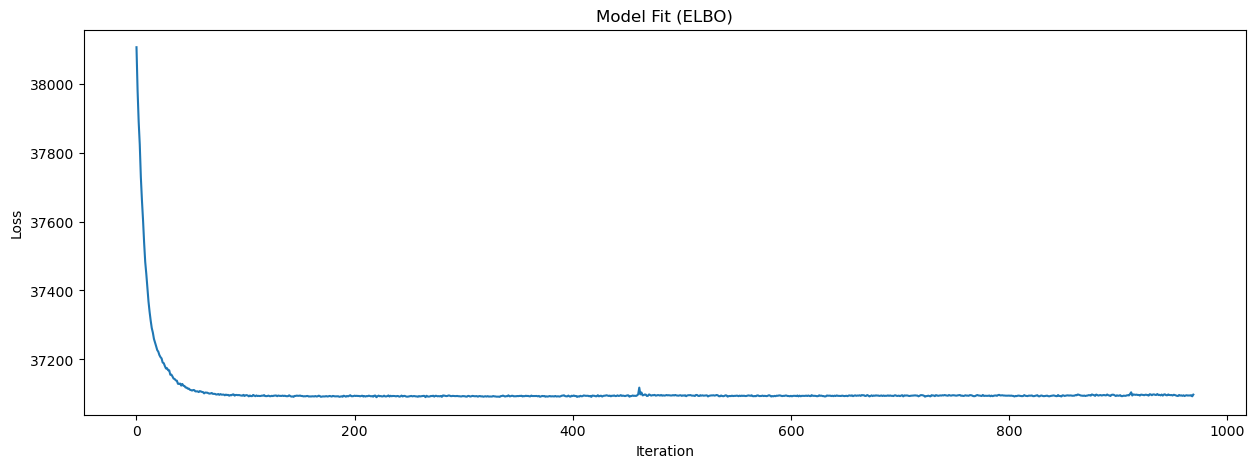

In [23]:
# plot convergence of ELBO bound (approximate value of the negative marginal log likelihood) and stores losses
fig, axes = plt.subplots(1, 1, figsize=(15, 5))
axes.plot(infer_recovery.loss[30:])  
axes.set_title("Model Fit (ELBO)")
axes.set_xlabel("Iteration")
axes.set_ylabel("Loss")
fig.savefig(path.join(recovery_dir, "ELBO.jpg"))

pd.DataFrame(infer_recovery.loss).to_csv(path.join(recovery_dir, "ELBO.csv"))

## 3. Statistical Evaluation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from os import path

# Load ground truth
gt_data = np.load(path.join(recovery_dir, 'recovery_ground_truth.npz'))
true_betas = gt_data['true_betas']
true_thetas = gt_data['true_thetas']
true_ks = gt_data['true_ks']
true_mixtures = gt_data['true_mixtures']
subject_ids = gt_data['subject_ids'].astype(str)

# Load recovery samples
rec_pars_df = pd.read_csv(path.join(recovery_dir, 'pars_post_samples_recovery.csv'), dtype={'ID':str})
m_prob_recovery = np.load(path.join(recovery_dir, 'm_prob_recovery.npy'))

In [ ]:
# Aggregate recovered parameters per subject (mean of posterior samples)

# 1. Continuous parameters
rec_avg_df = rec_pars_df.groupby('ID')[[r'$\\beta$', r'$\\theta$', r'$k$']].mean()
rec_avg_df = rec_avg_df.reindex(subject_ids)

recovered_betas = rec_avg_df[r'$\\beta$'].values
recovered_thetas = rec_avg_df[r'$\\theta$'].values
recovered_ks = rec_avg_df[r'$k$'].values

# 2. Planning Depths
n_unique_subjects = len(subject_ids)
mini_blocks = true_mixtures.shape[1]

# Transpose from (140, n_subjects, 3) to (n_subjects, 140, 3)
rec_mixtures = m_prob_recovery[0].transpose(1, 0, 2)

# Calculate mean planning depth for true and recovered mixtures
# Weighted sum: 1*p(depth=1) + 2*p(depth=2) + 3*p(depth=3) 
# Averaged across all mini-blocks to yield one scalar per subject
depth_weights = np.array([1, 2, 3])

true_mean_depth = (true_mixtures * depth_weights).sum(axis=-1).mean(axis=1)
recovered_mean_depth = (rec_mixtures * depth_weights).sum(axis=-1).mean(axis=1)

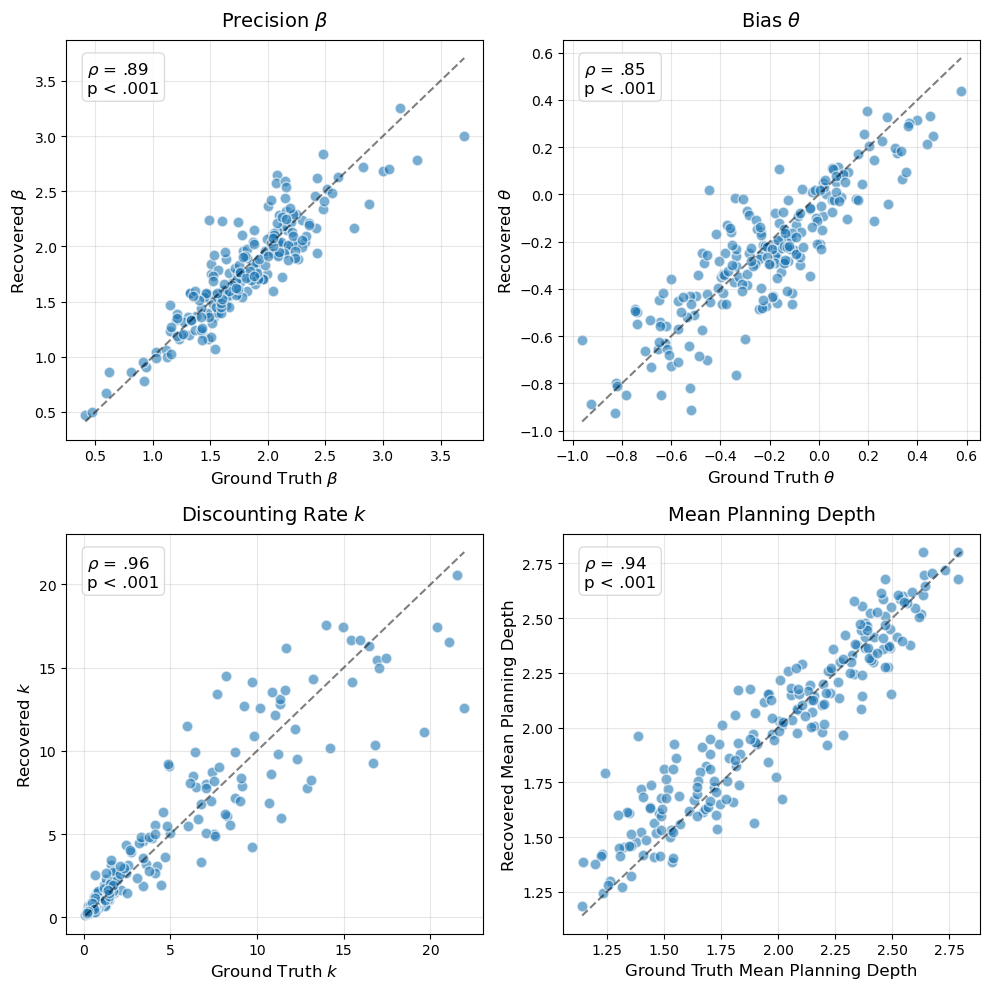

In [30]:
# =============================================================================
# VISUALIZATION (SCATTERPLOTS WITH APA STATISTICS)
# =============================================================================
def format_apa(r, p):
    # Formats stats to APA style (no leading zeros)
    r_str = f"r = {r:.2f}".replace("0.", ".")
    if p < .001:
        p_str = "p < .001"
    else:
        p_str = f"p = {p:.3f}".replace("0.", ".")
    return f"{r_str}\n{p_str}"

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes_flat = axes.flatten()

metrics = [
    (true_betas, recovered_betas, r'$\beta$', r'Precision $\beta$'),
    (true_thetas, recovered_thetas, r'$\theta$', r'Bias $\theta$'),
    (true_ks, recovered_ks, r'$k$', r'Discounting Rate $k$'),
    (true_mean_depth, recovered_mean_depth, 'Mean Planning Depth', 'Mean Planning Depth')
]

for ax, (true_vals, rec_vals, label, title) in zip(axes_flat, metrics):
    # Scatter points
    ax.scatter(true_vals, rec_vals, alpha=0.6, edgecolors='w', s=60)
    
    # Identity line (dashed)
    min_val = min(np.min(true_vals), np.min(rec_vals))
    max_val = max(np.max(true_vals), np.max(rec_vals))
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
    
    # Calculate stats & add text box
    r, p = spearmanr(true_vals, rec_vals)
    props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='lightgray')
    ax.text(0.05, 0.95, format_apa(r, p).replace('r =', r'$\rho$ ='), transform=ax.transAxes, fontsize=12,
            verticalalignment='top', bbox=props)
    
    # Aesthetics
    ax.set_xlabel(f'Ground Truth {label}', fontsize=12)
    ax.set_ylabel(f'Recovered {label}', fontsize=12)
    ax.set_title(f'{title}', fontsize=14, pad=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(path.join(recovery_dir, 'parameter_recovery_scatter.png'), dpi=300, bbox_inches='tight')
plt.show()